<h1><center>Практическое задание</h1></center>

1. Обучить модель анализа настроение с помощью GRU

In [1]:
import torch
from torch import nn
import seaborn as sns
from tqdm.notebook import tqdm
from torch.utils.data import Dataset, DataLoader, TensorDataset
from nltk.corpus import stopwords
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
import nltk
import itertools
import os
import copy

plt.rcParams.update({'font.size': 14})
sns.set_style('whitegrid')

<h2>Работа с датасетом

In [2]:
base_csv = 'D:/MIREA/DPO/Learning/Datasets/IMDB/IMDB Dataset.csv'
df = pd.read_csv(base_csv)
print(df.head(10))

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
5  Probably my all-time favorite movie, a story o...  positive
6  I sure would like to see a resurrection of a u...  positive
7  This show was an amazing, fresh & innovative i...  negative
8  Encouraged by the positive comments about this...  negative
9  If you like original gut wrenching laughter yo...  positive


In [11]:
df['review'][0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [3]:
print(np.mean([len(str) for str in df['review'].values]))

1309.43102


In [4]:
nltk.download('stopwords')


def preprocess_string(s):
    s = re.sub(r'[^\w\s]', '', s)
    s = re.sub(r'\s+', '', s)
    s = re.sub(r'\d', '', s)
    return s

def padding_(sentences, seq_len):
    features = np.zeros((len(sentences), seq_len), dtype=int)
    for ii, review in enumerate(sentences):
        if len(review) != 0:
            features[ii, -len(review):] = np.array(review)[:seq_len]
    return features

def tokenize(X_train, y_train, X_test, y_test):
    word_list = []
    stop_words = set(stopwords.words('english'))
    for sent in X_train:
        for word in sent.lower().split():
            word = preprocess_string(word)
            if word not in stop_words and word != '':
                word_list.append(word)

    corpora = Counter(word_list)
    corpora_ = sorted(corpora, key=corpora.get, reverse=True)[:1000]
    onehot_dict = {w: i + 1 for i, w in enumerate(corpora_)}

    final_list_train, final_list_test = [], []
    for sent in X_train:
        final_list_train.append([onehot_dict[preprocess_string(word)] for word in
                                 sent.lower().split() if preprocess_string(word) in onehot_dict.keys()])
    for sent in X_test:
        final_list_test.append([onehot_dict[preprocess_string(word)] for word in
                                 sent.lower().split() if preprocess_string(word) in onehot_dict.keys()])
        
    encoded_train = [1 if label == 'positive' else 0 for label in y_train]
    encoded_test = [1 if label == 'positive' else 0 for label in y_test]

    X_train_pad = padding_(final_list_train, 500)
    X_test_pad = padding_(final_list_test, 500)

    return X_train_pad, np.array(encoded_train), X_test_pad, np.array(encoded_test), onehot_dict


X, y = df['review'].values, df['sentiment'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y)
X_train, y_train, X_test, y_test, vocab = tokenize(X_train, y_train, X_test, y_test)

train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
valid_dataset = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

BATCH_SIZE = 60

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=True)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
sample_x, sample_y = next(iter(train_loader))

print('Sample input size: ', sample_x.size())
print('Sample input: \n', sample_x)
print('Sample input: \n', sample_y)
print('Sample input size: ', sample_y.size())

Sample input size:  torch.Size([60, 500])
Sample input: 
 tensor([[  0,   0,   0,  ...,   4,  39, 111],
        [  0,   0,   0,  ..., 543, 135, 219],
        [  0,   0,   0,  ..., 522, 393, 260],
        ...,
        [  0,   0,   0,  ..., 681,  24, 426],
        [  0,   0,   0,  ...,   2,  52, 270],
        [  0,   0,   0,  ..., 715, 626, 413]])
Sample input: 
 tensor([1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0,
        1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
        0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0])
Sample input size:  torch.Size([60])


<h2>Архитектура модели</h2>

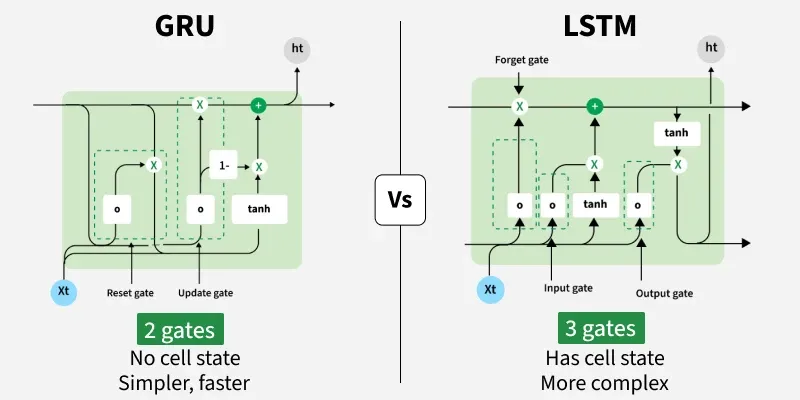

In [6]:
class SentimentGRU(nn.Module):
    def __init__(self, no_layers, vocab_size, hidden_dim,
                 output_dim, embedding_dim, drop_prob=.3):
        super(SentimentGRU, self).__init__()
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim
        self.embedding_dim = embedding_dim
        self.no_layers = no_layers
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_dim,
                          num_layers=no_layers, batch_first=True)
        self.dropout = nn.Dropout(drop_prob)
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.sig = nn.Sigmoid()

    def forward(self, x):
        batch_size = x.size(0)
        hidden = torch.zeros((self.no_layers, x.size(0), self.hidden_dim)).to(x.device)
        embeds = self.embedding(x)
        lstm_out, hidden = self.gru(embeds, hidden)
        lstm_out = lstm_out.contiguous().view(-1, self.hidden_dim)
        out = self.dropout(lstm_out)
        out = self.fc(out)
        sig_out = self.sig(out)
        sig_out = sig_out.view(batch_size, -1)
        sig_out = sig_out[:, -1]
        return sig_out

In [ ]:
def acc(pred, label):
    pred = torch.round(pred.squeeze())
    return torch.sum(pred == label.squeeze()).item()

def train_sent_gru(model, criterion, optimizer, scheduler, num_epochs,
                   clip, train_loader, valid_loader, device,
                   start_epoch = 0, is_output_values_epochs = False,
                   is_output_values_end = True, patience = 2):
    history = {
        'train_loss': [], 'train_acc': [],
        'valid_loss': [], 'valid_acc': []
    }

    best_valid_loss = np.inf
    best_model_weights = None
    patience_counter = 0

    for epoch in tqdm(range(num_epochs)):
        train_losses = []
        train_acc = 0.0
        model.train()

        for inputs, labels in tqdm(train_loader, 'Training'):
            inputs, labels = inputs.to(device), labels.to(device)

            model.zero_grad()
            outputs = model(inputs)

            loss = criterion(outputs, labels.float())
            loss.backward()
            train_losses.append(loss.item())
            train_acc += acc(outputs, labels)
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
        
        with torch.inference_mode():
            val_losses = []
            val_acc = 0.0
            model.eval()

            for inputs, labels in tqdm(valid_loader, desc='Validation'):
                inputs, labels = inputs.to(device), labels.to(device)
                
                outputs = model(inputs)
                
                val_loss = criterion(outputs, labels.float())
                val_losses.append(val_loss.item())
                val_acc += acc(outputs, labels)
        

        epoch_train_loss = np.mean(train_losses)
        epoch_train_acc = train_acc / len(train_loader.dataset)
        epoch_val_loss = np.mean(val_losses)
        epoch_val_acc = val_acc / len(valid_loader.dataset)

        scheduler.step(epoch_val_loss)

        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['valid_loss'].append(epoch_val_loss)
        history['valid_acc'].append(epoch_val_acc)

        if is_output_values_epochs:
            print(f'EPOCH {(epoch + 1):02d} model: Train Loss: {epoch_train_loss:.3f} | Train Acc: {epoch_train_acc:.3f} | Val Loss: {epoch_val_loss:.3f} | Val Acc: {epoch_val_acc:.3f}.')
        
        if best_valid_loss > epoch_val_loss:
            best_valid_loss = epoch_val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        elif (epoch_val_loss - best_valid_loss) <= 4e-2:
            patience_counter += 1
        else:
            print(f'EPOCH: {(epoch + 1):02d}: To high valid loss.')
            break
        
        if patience_counter >= patience:
            print(f'EPOCH: {(epoch + 1):02d}: Early stopping, patience out.')
            break

    return history, best_model_weights

def hyperparams(backup_csv_path = 'hyperparams_report.csv', start_idx = 0):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Current device: ', device)

    vocab_size = len(vocab) + 1
    output_dim = 1

    param_grid = {
        'no_layers': [1, 2, 3],
        'embedding_dim': [64, 128],
        'hidden_dim': [128, 256, 512],
        'drop_prob': [0.3, 0.5]
    }

    keys, values = param_grid.keys(), param_grid.values()
    combinations = list(itertools.product(*values))
    all_models_results = []
    lr = 1e-3

    for i, v in enumerate(tqdm(combinations, desc='Trying various hyperparameters')):
        idx = start_idx + i
        params = dict(zip(keys, v))
        model = SentimentGRU(
            no_layers=params['no_layers'],
            vocab_size=vocab_size,
            hidden_dim=params['hidden_dim'],
            output_dim=output_dim,
            embedding_dim=params['embedding_dim'],
            drop_prob=params['drop_prob']
            )
        num_params = sum(p.numel() for p in model.parameters())
        try:
            print(f'Model:\nno_layers={params["no_layers"]}, vocab_size={vocab_size},\
    hidden_dim={params["hidden_dim"]}, output_dim={output_dim}, \
    embedding_dim={params["embedding_dim"]}, drop_prob={params["drop_prob"]}')
            model.to(device)
            

            criterion = nn.BCELoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=lr)
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

            clip = 5
            num_epochs = 10
            valid_loss_min = np.inf

            history, best_model_weights = train_sent_gru(model, criterion, optimizer, scheduler, num_epochs,
                                    clip, train_loader, valid_loader, device)
            
            torch.save(model.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_14/gru_end_{idx}.pt')
            if best_model_weights is not None:
                torch.save(best_model_weights, f'D:/MIREA/DPO/Learning/Practic2_14/gru_best_{idx}.pt')

            best_epoch_idx = np.argmax(history['valid_acc'])

            result_entry = {
                'model_idx': idx,
                'no_layers': params['no_layers'],
                'vocab_size': vocab_size,
                'hidden_dim': params['hidden_dim'],
                'output_dim': output_dim,
                'embedding_dim': params['embedding_dim'],
                'drop_prod': params['drop_prob'],
                'total_params': num_params,
                'best_train_loss': history['train_loss'][best_epoch_idx],
                'best_train_acc': history['train_acc'][best_epoch_idx],
                'best_valid_loss': history['valid_loss'][best_epoch_idx],
                'best_valid_acc': history['valid_acc'][best_epoch_idx],
                'full_history': history,
                'status': 'Success'
            }
        except RuntimeError as e:
            if 'out of memory' in str(e).lower():
                print(f'/nAlarm, not enough memory for this model')
                
                del model
                torch.cuda.empty_cache()

                result_entry = {
                    'model_idx': idx, 'no_layers': params['no_layers'], 'vocab_size': vocab_size,
                    'hidden_dim': params['hidden_dim'], 'output_dim': output_dim, 'embedding_dim': params['embedding_dim'],
                    'drop_prob': params['drop_prob'], 'total_params': num_params,
                    'best_train_loss': None, 'best_train_acc': None, 'best_valid_loss': None, 'best_valid_acc': None,
                    'status': 'CUDA OOM'
                }
            else:
                raise e

        all_models_results.append(result_entry)
        df_single_row = pd.DataFrame([result_entry])
        
        if not os.path.isfile(backup_csv_path):
            df_single_row.to_csv(backup_csv_path, index=False)
        else:
            df_single_row.to_csv(backup_csv_path, mode='a', header=False, index=False)

In [8]:
# hyperparams(backup_csv_path='hyperparams_report_attempt2.csv')

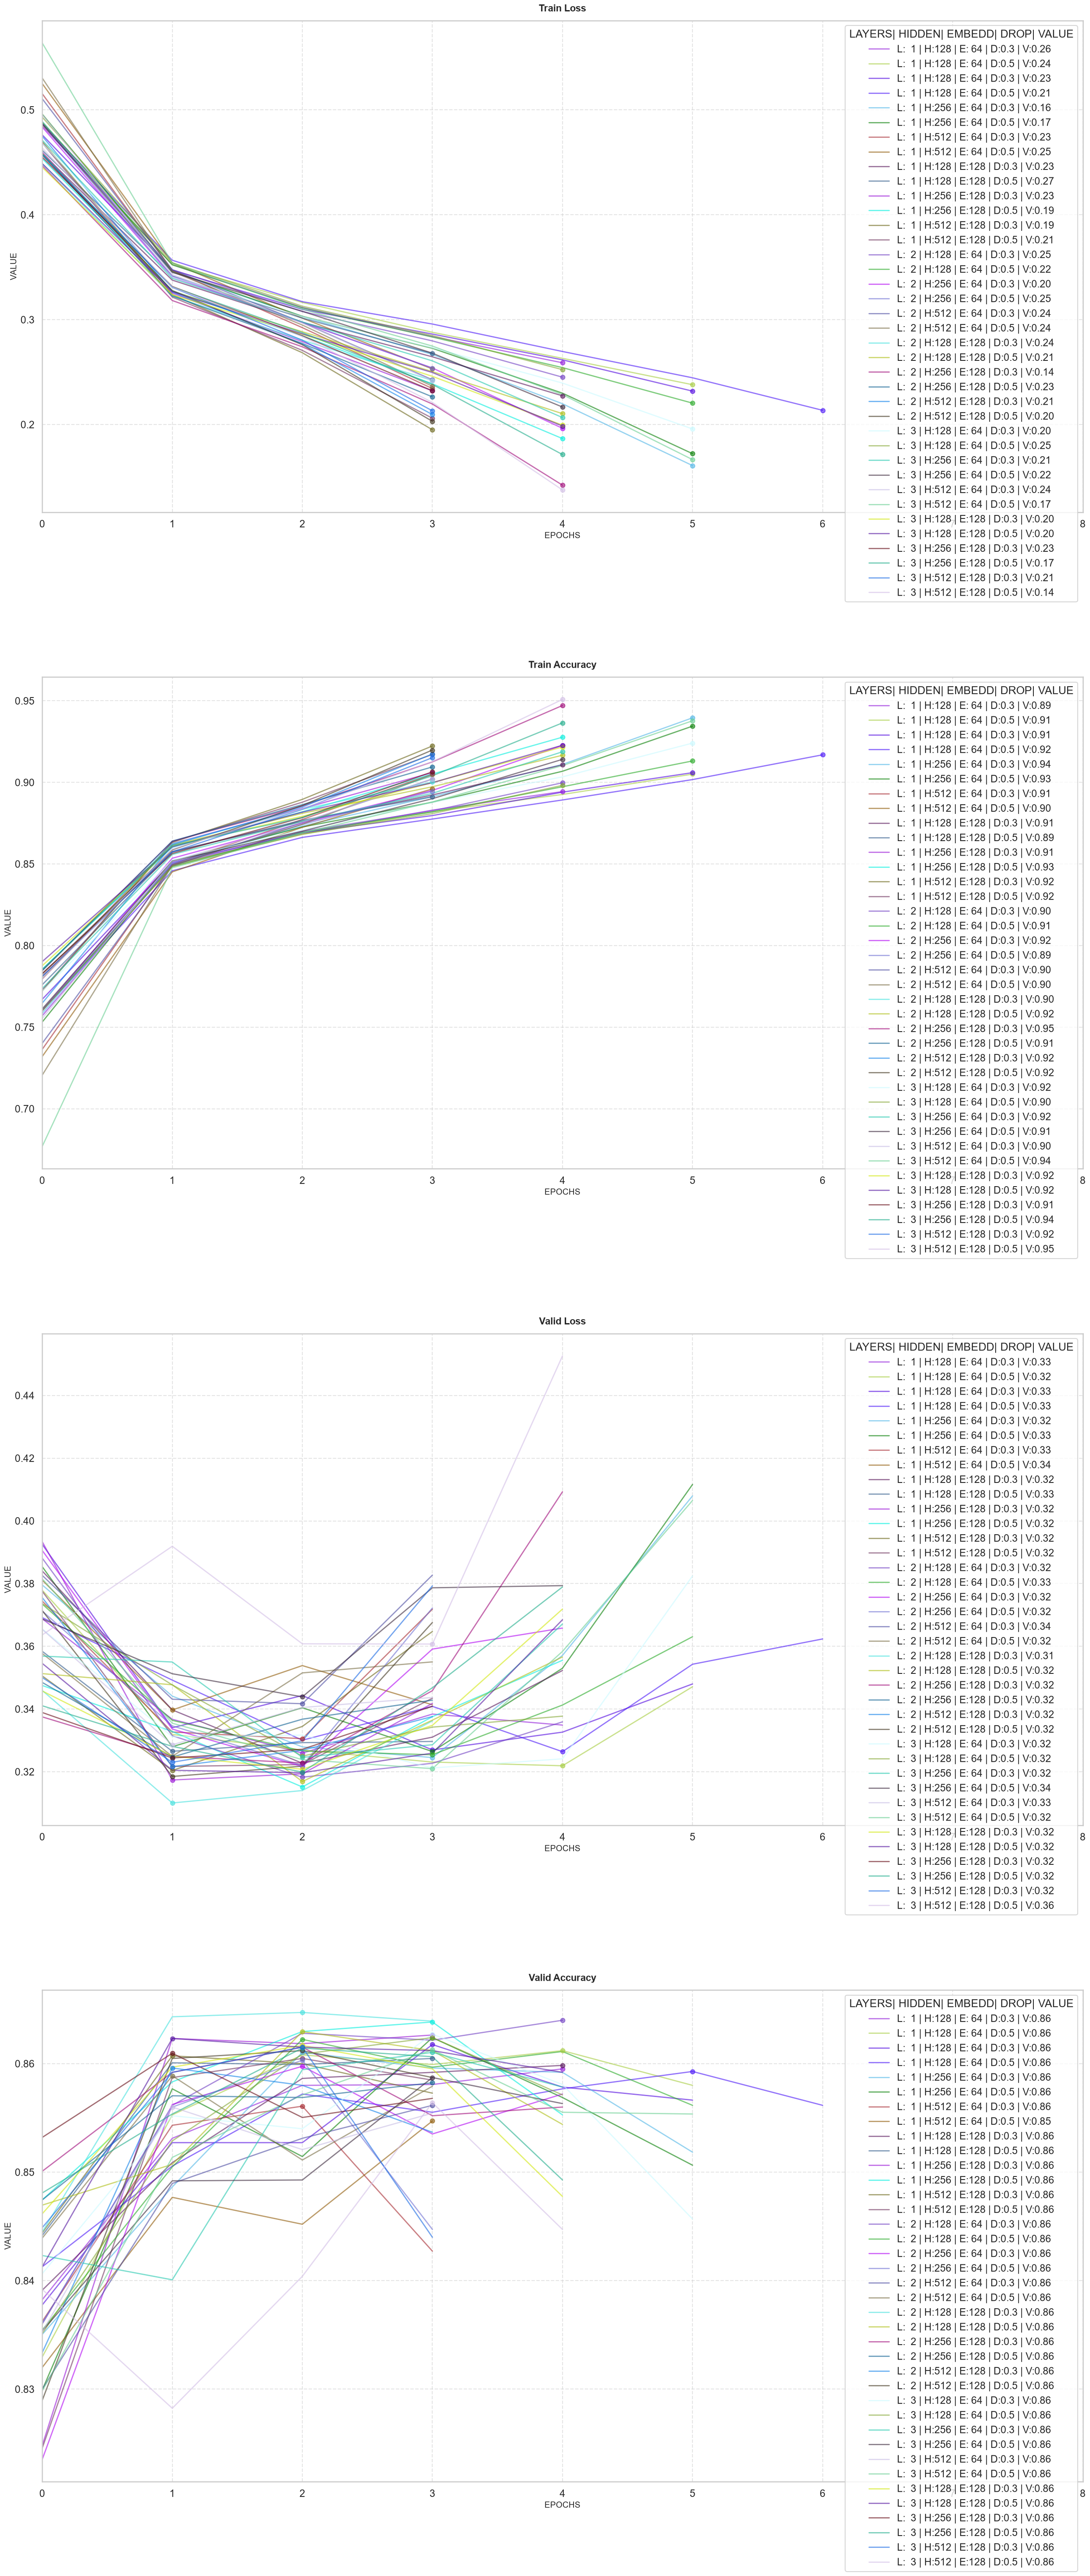

In [12]:
import ast
import re


sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 16})


df = pd.read_csv('hyperparams_report_attempt2.csv')

full_history = []

for i in df['full_history']:
    clean_history_str = re.sub(r'np\.float64\((.*?)\)', r'\1', i)
    add_dict = ast.literal_eval(clean_history_str)
    full_history.append(add_dict)


fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(25, 60))
titles = ['Train Loss', 'Train Accuracy', 'Valid Loss', 'Valid Accuracy']
history_keys = ['train_loss', 'train_acc', 'valid_loss', 'valid_acc']
count_values = df.shape[0]
max_len = max(max(len(i) for i in j.values()) for j in full_history)
COLORS = np.random.uniform(0, 1, size=(count_values, 3))

for j, key in enumerate(full_history[0].keys()):
    ax[j].set_xlabel('EPOCHS')
    ax[j].set_ylabel('VALUE')
    ax[j].set_title(titles[j], pad=15, weight='bold')
    ax[j].set_xlim(0, max_len + 1)
    legend_labels = {}

    for i in range(count_values):
        data = full_history[i][key]

        if key[-3:] == 'acc':
            index, value = max(enumerate(data), key = lambda x: x[1])
        else: 
            index, value = min(enumerate(data), key = lambda x: x[1])
        ax[j].scatter(index, value, color=COLORS[i], alpha=0.6, s=50, zorder=5)

        h_dim = df.loc[i, 'hidden_dim']
        layers = df.loc[i, 'no_layers']
        drop = df.loc[i, 'drop_prod']
        emb = df.loc[i, 'embedding_dim']
        label_text = f'L:{layers:3d} | H:{h_dim:3d} | E:{emb:3d} | D:{drop:.1f} | V:{value:.2f}'

        line = ax[j].plot(range(len(data)), data, color=COLORS[i], alpha=0.6, linewidth=2, label=label_text)
        legend_labels[label_text] = line[0]
        
        ax[j].plot()
    
    handles, labels = ax[j].get_legend_handles_labels()
    
    ax[j].legend(handles, labels, title='LAYERS| HIDDEN| EMBEDD| DROP| VALUE')
    ax[j].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [53]:
def tokenize_texts(X):
    word_list = []
    stop_words = set(stopwords.words('english'))
    for sent in X:
        for word in sent.lower().split():
            word = preprocess_string(word)
            if word not in stop_words and word != '':
                word_list.append(word)

    corpora = Counter(word_list)
    corpora_ = sorted(corpora, key = corpora.get, reverse=True)[:1000]
    onehot_dict = {w: i + 1 for i, w in enumerate(corpora_)}

    final_list = []
    for sent in X:
        final_list.append([onehot_dict[preprocess_string(word)] for word in
                           sent.lower().split() if preprocess_string(word) in onehot_dict.keys()])
    X_out = padding_(final_list, 500)
    return X_out 


model_18_state_dict = torch.load('D:/MIREA/DPO/Learning/Practic2_14/gru_best_18.pt')
model_18 = SentimentGRU(no_layers=2, vocab_size=len(vocab) + 1, hidden_dim=128,
                        output_dim=1, embedding_dim=128, drop_prob=.3)
model_18.load_state_dict(model_18_state_dict)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_18.to(device)

text = np.array(["Oh yeah, good film, bad film, oh yeah"])
text = tokenize_texts(text)
text_dataset = TensorDataset(torch.from_numpy(text))
text_loader = DataLoader(text_dataset, batch_size=BATCH_SIZE)

with torch.inference_mode():
    model_18.eval()
    for (inputs, ) in text_loader:
        inputs = inputs.to(device)
        
        outputs = model_18(inputs)
        
        print(outputs)


tensor([0.5764], device='cuda:0')
